##### Copyright 2021 The TensorFlow Authors.

In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Generate music with an RNN

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/audio/music_generation"><img src="https://www.tensorflow.org/images/tf_logo_32px.png" />View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/audio/music_generation.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

This tutorial shows you how to generate musical notes using a simple recurrent neural network (RNN). You will train a model using a collection of piano MIDI files from the [MAESTRO dataset](https://magenta.tensorflow.org/datasets/maestro). Given a sequence of notes, your model will learn to predict the next note in the sequence. You can generate longer sequences of notes by calling the model repeatedly.

This tutorial contains complete code to parse and create MIDI files. You can learn more about how RNNs work by visiting the [Text generation with an RNN](https://www.tensorflow.org/text/tutorials/text_generation) tutorial.

## Setup

This tutorial uses the [`pretty_midi`](https://github.com/craffel/pretty-midi) library to create and parse MIDI files, and [`pyfluidsynth`](https://github.com/nwhitehead/pyfluidsynth) for generating audio playback in Colab.

In [5]:
!sudo apt install -y fluidsynth

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-core fluid-soundfont-gm gsettings-desktop-schemas libatk-bridge2.0-0
  libatk1.0-0 libatk1.0-data libatspi2.0-0 libdouble-conversion3 libevdev2
  libfluidsynth3 libgtk-3-0 libgtk-3-bin libgtk-3-common libgudev-1.0-0
  libinput-bin libinput10 libinstpatch-1.0-2 libmd4c0 libmtdev1 libqt5core5a
  libqt5dbus5 libqt5gui5 libqt5network5 libqt5svg5 libqt5widgets5
  librsvg2-common libwacom-bin libwacom-common libwacom9 libxcb-icccm4
  libxcb-image0 libxcb-keysyms1 libxcb-render-util0 libxcb-util1
  libxcb-xinerama0 libxcb-xinput0 libxcb-xkb1 libxcomposite1
  libxkbcommon-x11-0 libxtst6 qsynth qt5-gtk-platformtheme
  qttranslations5-l10n session-migration timgm6mb-soundfont
Suggested packages:
  fluid-soundfont-gs gvfs qt5-image-formats-plugins qtwayland5 jackd
The following NEW packages will be installed:
  at-spi2-core fluid-soundfont

In [6]:
!pip install --upgrade pyfluidsynth

In [7]:
!pip install pretty_midi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 89.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 5.5 MB/s eta 0:00:00
  Created wheel for pretty_midi: filename=pretty_midi-0.2.11-py3-none-any.whl size=5595886 sha256=857767bd09d59b8a6eeb1ff58fa0718eb9c02ba341202850a89d7849f7d715bd
  Stored in directory: /root/.cache/pip/wheels/f4/ad/93/a7042fe12668827574927ade9deec7f29aad2a1001b1501882
Successfully built pretty_midi


In [8]:
import collections
import datetime
import fluidsynth
import glob
import numpy as np
import pathlib
import pandas as pd
import pretty_midi
import seaborn as sns
import tensorflow as tf

from IPython import display
from matplotlib import pyplot as plt
from typing import Optional

In [9]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

# Sampling rate for audio playback
_SAMPLING_RATE = 16000

## Download the Maestro dataset

In [10]:
def midi_to_notes(midi_file: str) -> pd.DataFrame:
  pm = pretty_midi.PrettyMIDI(midi_file)
  instrument = pm.instruments[0]
  notes = collections.defaultdict(list)

  # Sort the notes by start time
  sorted_notes = sorted(instrument.notes, key=lambda note: note.start)
  prev_start = sorted_notes[0].start

  for note in sorted_notes:
    start = note.start
    end = note.end
    notes['pitch'].append(note.pitch)
    notes['start'].append(start)
    notes['end'].append(end)
    notes['step'].append(start - prev_start)
    notes['duration'].append(end - start)
    prev_start = start

  return pd.DataFrame({name: np.array(value) for name, value in notes.items()})

In [11]:
import os

print('Renaming .mid files to .midi in /content directory...')
for filename in os.listdir('/content'):
    if filename.endswith('.mid'):
        old_path = os.path.join('/content', filename)
        new_filename = filename.replace('.mid', '.midi')
        new_path = os.path.join('/content', new_filename)
        os.rename(old_path, new_path)
        print(f'Renamed {filename} to {new_filename}')
print('Renaming complete.')

Renaming .mid files to .midi in /content directory...
Renaming complete.


In [12]:
import pathlib
import os
import glob

# Define the specific directory for melody samples
melody_dir = pathlib.Path('/content/sample_data/Melody')

# Ensure directory exists and rename files if necessary
if melody_dir.exists():
    for filename in os.listdir(melody_dir):
        if filename.endswith('.mid'):
            old_path = os.path.join(melody_dir, filename)
            new_path = os.path.join(melody_dir, filename.replace('.mid', '.midi'))
            os.rename(old_path, new_path)

# Collect filenames from the specific Melody directory
melody_filenames = glob.glob(str(melody_dir/'*.midi'))
print(f'Found {len(melody_filenames)} melody files in {melody_dir}')

Found 0 melody files in /content/sample_data/Melody


In [13]:
!pip install pretty_midi
import collections
import pandas as pd
import numpy as np
import pretty_midi
import tensorflow as tf

# Defining constants locally to avoid NameError
key_order = ['pitch', 'step', 'duration']
seq_length = 64
vocab_size = 128
batch_size = 64

def create_sequences(
    dataset: tf.data.Dataset,
    seq_length: int,
    vocab_size = 128,
) -> tf.data.Dataset:
  """Returns TF Dataset of sequence and label examples."""
  seq_length = seq_length+1
  windows = dataset.window(seq_length, shift=1, stride=1, drop_remainder=True)
  flatten = lambda x: x.batch(seq_length, drop_remainder=True)
  sequences = windows.flat_map(flatten)

  def scale_pitch(x):
    x = x/[vocab_size, 1.0, 1.0]
    return x

  def split_labels(sequences):
    inputs = sequences[:-1]
    labels_dense = sequences[-1]
    labels = {key:labels_dense[i] for i,key in enumerate(key_order)}
    return scale_pitch(inputs), labels

  return sequences.map(split_labels, num_parallel_calls=tf.data.AUTOTUNE)

def midi_to_notes(midi_file: str) -> pd.DataFrame:
  pm = pretty_midi.PrettyMIDI(midi_file)
  instrument = pm.instruments[0]
  notes = collections.defaultdict(list)
  sorted_notes = sorted(instrument.notes, key=lambda note: note.start)
  if not sorted_notes: return pd.DataFrame()
  prev_start = sorted_notes[0].start
  for note in sorted_notes:
    start = note.start
    end = note.end
    notes['pitch'].append(note.pitch)
    notes['start'].append(start)
    notes['end'].append(end)
    notes['step'].append(start - prev_start)
    notes['duration'].append(end - start)
    prev_start = start
  return pd.DataFrame({name: np.array(value) for name, value in notes.items()})

# Extract notes only from the Melody folder
all_melody_notes = []
for f in melody_filenames:
    try:
        notes = midi_to_notes(f)
        if not notes.empty:
            all_melody_notes.append(notes)
    except Exception as e:
        print(f'Error processing {f}: {e}')

if all_melody_notes:
    all_notes = pd.concat(all_melody_notes)
    n_notes = len(all_notes)
    print(f'Total notes for pure melody training: {n_notes}')

    # Update training variables
    train_notes = np.stack([all_notes[key] for key in key_order], axis=1)
    notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)

    # Sequence creation
    seq_ds = create_sequences(notes_ds, seq_length, vocab_size)

    buffer_size = n_notes - seq_length
    train_ds = (seq_ds
                .shuffle(buffer_size)
                .batch(batch_size, drop_remainder=True)
                .cache()
                .prefetch(tf.data.experimental.AUTOTUNE))
    print('Dataset prepared successfully.')
else:
    print('Warning: No melody files found or files are empty.')

### Transposing all melodies to C Major / A Minor
To avoid "atonal" generation, we shift every MIDI file so they all share the same key center. This helps the RNN learn melodic patterns much faster.

In [23]:
import glob
import pathlib
import pretty_midi
import numpy as np
import pandas as pd
import collections
import tensorflow as tf

# 1. Using the correct path verified by previous successful execution
melody_dir = pathlib.Path('/content/Solo')
melody_filenames = glob.glob(str(melody_dir/'*.mid'))
seq_length = 64
vocab_size = 128
batch_size = 64

def transpose_to_c(midi_file):
    pm = pretty_midi.PrettyMIDI(midi_file)
    if not pm.instruments or not pm.instruments[0].notes:
        return pm
    total_velocity = np.zeros(12)
    for note in pm.instruments[0].notes:
        total_velocity[note.pitch % 12] += note.velocity
    key_center = np.argmax(total_velocity)
    shift = 0 - key_center
    for instrument in pm.instruments:
        for note in instrument.notes:
            note.pitch += shift
    return pm

all_melody_notes = []
print(f"Normalizing {len(melody_filenames)} files from {melody_dir} to C Major / A Minor...")

if not melody_filenames:
    print("Error: No MIDI files found! Please check the folder /content/Solo/")
else:
    for f in melody_filenames:
        try:
            pm_c = transpose_to_c(f)
            instrument = pm_c.instruments[0]
            notes_dict = collections.defaultdict(list)
            sorted_notes = sorted(instrument.notes, key=lambda note: note.start)
            if not sorted_notes: continue
            prev_start = sorted_notes[0].start
            for note in sorted_notes:
                notes_dict['pitch'].append(note.pitch)
                notes_dict['step'].append(note.start - prev_start)
                notes_dict['duration'].append(note.end - note.start)
                prev_start = note.start
            all_melody_notes.append(pd.DataFrame(notes_dict))
        except Exception as e:
            print(f'Error processing {f}: {e}')

    if all_melody_notes:
        all_notes = pd.concat(all_melody_notes)
        key_order = ['pitch', 'step', 'duration']
        train_notes = np.stack([all_notes[key] for key in key_order], axis=1)
        notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)

        # seq_ds creation
        seq_ds = create_sequences(notes_ds, seq_length, vocab_size)

        train_ds = (seq_ds
                    .shuffle(len(all_notes))
                    .batch(batch_size, drop_remainder=True)
                    .cache()
                    .prefetch(tf.data.experimental.AUTOTUNE))

        print(f'Done! Prepared {len(all_notes)} transposed notes in train_ds.')
    else:
        print("No notes were extracted.")

Normalizing 27 files from /content/Solo to C Major / A Minor...
Done! Prepared 3460 transposed notes in train_ds.


In [15]:
import glob
import pathlib

# Define data_dir to fix the NameError
data_dir = pathlib.Path('/content')

# Updated pattern to specifically look for .midi files
filenames = glob.glob(str(data_dir/'*.midi'))
print('Number of files after renaming and re-globbing:', len(filenames))

Number of files after renaming and re-globbing: 0


In [16]:
# Update filenames from the successful melody search
filenames = melody_filenames

if len(filenames) > 1:
    sample_file = filenames[1]
    print('Sample file selected:', sample_file)
else:
    print(f'Warning: Not enough files found. Current count: {len(filenames)}')

In [20]:
import glob
import pandas as pd

# Correcting the path to the actual location of your MIDI files
filenames = glob.glob('/content/Solo/*.mid')

num_files = 5
all_notes = []

if not filenames:
    print("Error: No MIDI files found in /content/Solo/. Check your file paths.")
else:
    for f in filenames[:num_files]:
        try:
            notes = midi_to_notes(f)
            if not notes.empty:
                all_notes.append(notes)
        except Exception as e:
            print(f"Could not process {f}: {e}")

    if all_notes:
        all_notes = pd.concat(all_notes)
        n_notes = len(all_notes)
        print('Number of notes parsed:', n_notes)
    else:
        print("No notes were extracted from the found files.")

Number of notes parsed: 888


In [21]:
import os

# Categorize files based on keywords in filenames
categories = {
    'solo': [],
    'chords': [],
    'strings': [],
    'other': []
}

for f in filenames:
    fname = f.lower()
    if 'solo' in fname or 'zurna' in fname or 'sax' in fname or 'melody' in fname:
        categories['solo'].append(f)
    elif 'chords' in fname or 'organ' in fname:
        categories['chords'].append(f)
    elif 'strings' in fname:
        categories['strings'].append(f)
    else:
        categories['other'].append(f)

print(f"Found {len(categories['solo'])} Solo tracks")
print(f"Found {len(categories['chords'])} Chord tracks")
print(f"Found {len(categories['strings'])} String tracks")

Found 27 Solo tracks
Found 0 Chord tracks
Found 0 String tracks


### Training ONLY on Solo tracks
Now we extract notes exclusively from the solo category to provide the model with a clear melodic structure.

In [22]:
all_solo_notes = []
for f in categories['solo']:
    notes = midi_to_notes(f)
    all_solo_notes.append(notes)

all_notes = pd.concat(all_solo_notes)
n_notes = len(all_notes)
print(f'Number of Solo notes for training: {n_notes}')

# Update the training data variable for the rest of the pipeline
train_notes = np.stack([all_notes[key] for key in key_order], axis=1)
notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)
seq_ds = create_sequences(notes_ds, seq_length, vocab_size)

buffer_size = n_notes - seq_length
train_ds = (seq_ds
            .shuffle(buffer_size)
            .batch(batch_size, drop_remainder=True)
            .cache()
            .prefetch(tf.data.experimental.AUTOTUNE))

Number of Solo notes for training: 3460


In [24]:
import pathlib

data_dir = pathlib.Path('/content')
# Removed Maestro dataset download logic as we are using local files.

The dataset contains about 1,200 MIDI files.

In [25]:
filenames = glob.glob(str(data_dir/'*.mid*')) # Adjusted glob pattern to search directly in /content
print('Number of files:', len(filenames))

Number of files: 0


In [26]:
print('Checking the directory structure to locate the MIDI files:')
!ls -R /content

Checking the directory structure to locate the MIDI files:
/content:
sample_data  Solo

/content/sample_data:
anscombe.json		      mnist_test.csv
california_housing_test.csv   mnist_train_small.csv
california_housing_train.csv  README.md

/content/Solo:
BalkanPrincess_Gmin_Solo.mid	   Mesechina_Gmin_Solo.mid
Barman_Bmin.mid			   Moryache_Gmin.mid
Blyan_Gmin_Melody.mid		   MrSaxoParty_Bmin.mid
Borets_A#min_Zurna.mid		   Oblache_A#min.mid
CareFree_G#min.mid		   Potaen_Cmin.mid
Dragostea_Amin_Solo.mid		   Razboinik_Cmin.mid
Glava_Emin.mid			   Seltze_Gmin.mid
GypsyOrgan_F#PhyrgianDominant.mid  Sokol_Cmin_Solo.mid
Kemane_Dmin_Solo.mid		   TallavaBoy_Cmin.mid
KocekParty_D#Phyrgian.mid	   Vesela_GMaj.mid
Lale_C#min.mid			   Waves_Cmin.mid
LoveLetters_G#min_Solo.mid	   Yugoslavia_Fmin.mid
Megdan_Cmin.mid			   Zornitsa_Dmin_Sax.mid
Mehana_FPhyrgianDominant.mid


## Process a MIDI file

First, use ```pretty_midi``` to parse a single MIDI file and inspect the format of the notes. If you would like to download the MIDI file below to play on your computer, you can do so in colab by writing ```files.download(sample_file)```.


In [27]:
# Update filenames to the list that contains the melody files
filenames = melody_filenames

# Check if we have enough files before accessing index 1
if len(filenames) > 1:
    sample_file = filenames[1]
    print(f"Sample file selected: {sample_file}")
else:
    print(f"Error: Found {len(filenames)} files. Need at least 2 to pick the second one.")

Sample file selected: /content/Solo/Kemane_Dmin_Solo.mid


Generate a `PrettyMIDI` object for the sample MIDI file.

In [28]:
pm = pretty_midi.PrettyMIDI(sample_file)

Play the sample file. The playback widget may take several seconds to load.

In [29]:
def display_audio(pm: pretty_midi.PrettyMIDI, seconds=30):
  waveform = pm.fluidsynth(fs=_SAMPLING_RATE)
  # Take a sample of the generated waveform to mitigate kernel resets
  waveform_short = waveform[:seconds*_SAMPLING_RATE]
  return display.Audio(waveform_short, rate=_SAMPLING_RATE)

In [30]:
display_audio(pm)

Do some inspection on the MIDI file. What kinds of instruments are used?

In [31]:
print('Number of instruments:', len(pm.instruments))
instrument = pm.instruments[0]
instrument_name = pretty_midi.program_to_instrument_name(instrument.program)
print('Instrument name:', instrument_name)

Number of instruments: 1
Instrument name: Acoustic Grand Piano


## Extract notes

In [32]:
for i, note in enumerate(instrument.notes[:10]):
  note_name = pretty_midi.note_number_to_name(note.pitch)
  duration = note.end - note.start
  print(f'{i}: pitch={note.pitch}, note_name={note_name},'
        f' duration={duration:.4f}')

0: pitch=62, note_name=D4, duration=0.0625
1: pitch=67, note_name=G4, duration=0.0781
2: pitch=69, note_name=A4, duration=0.0938
3: pitch=69, note_name=A4, duration=0.1562
4: pitch=67, note_name=G4, duration=0.0625
5: pitch=69, note_name=A4, duration=0.0625
6: pitch=67, note_name=G4, duration=0.2448
7: pitch=69, note_name=A4, duration=0.1458
8: pitch=67, note_name=G4, duration=0.0938
9: pitch=65, note_name=F4, duration=0.1146


You will use three variables to represent a note when training the model: `pitch`, `step` and `duration`. The pitch is the perceptual quality of the sound as a MIDI note number.
The `step` is the time elapsed from the previous note or start of the track.
The `duration` is how long the note will be playing in seconds and is the difference between the note end and note start times.


Extract the notes from the sample MIDI file.

In [33]:
def midi_to_notes(midi_file: str) -> pd.DataFrame:
  pm = pretty_midi.PrettyMIDI(midi_file)
  instrument = pm.instruments[0]
  notes = collections.defaultdict(list)

  # Sort the notes by start time
  sorted_notes = sorted(instrument.notes, key=lambda note: note.start)
  prev_start = sorted_notes[0].start

  for note in sorted_notes:
    start = note.start
    end = note.end
    notes['pitch'].append(note.pitch)
    notes['start'].append(start)
    notes['end'].append(end)
    notes['step'].append(start - prev_start)
    notes['duration'].append(end - start)
    prev_start = start

  return pd.DataFrame({name: np.array(value) for name, value in notes.items()})

In [34]:
raw_notes = midi_to_notes(sample_file)
raw_notes.head()

,pitch,start,end,step,duration
0,62,0.375000,0.437500,0.000000,0.062500
1,67,0.463542,0.541667,0.088542,0.078125
2,69,0.510417,0.604167,0.046875,0.093750
3,69,0.750000,0.906250,0.239583,0.156250
4,67,1.000000,1.062500,0.250000,0.062500


In [35]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=raw_notes)

https://docs.google.com/spreadsheets/d/1ZZQQMP0XYUfIvzY3eorN31_LmLytyycwstibWFPSg2I/edit#gid=0


It may be easier to interpret the note names rather than the pitches, so you can use the function below to convert from the numeric pitch values to note names.
The note name shows the type of note, accidental and octave number
(e.g. C#4).

In [36]:
get_note_names = np.vectorize(pretty_midi.note_number_to_name)
sample_note_names = get_note_names(raw_notes['pitch'])
sample_note_names[:10]

array(['D4', 'G4', 'A4', 'A4', 'G4', 'A4', 'G4', 'A4', 'G4', 'F4'],
      dtype='<U3')

To visualize the musical piece, plot the note pitch, start and end across the length of the track (i.e. piano roll). Start with the first 100 notes

In [37]:
def plot_piano_roll(notes: pd.DataFrame, count: Optional[int] = None):
  if count:
    title = f'First {count} notes'
  else:
    title = f'Whole track'
    count = len(notes['pitch'])
  plt.figure(figsize=(20, 4))
  plot_pitch = np.stack([notes['pitch'], notes['pitch']], axis=0)
  plot_start_stop = np.stack([notes['start'], notes['end']], axis=0)
  plt.plot(
      plot_start_stop[:, :count], plot_pitch[:, :count], color="b", marker=".")
  plt.xlabel('Time [s]')
  plt.ylabel('Pitch')
  _ = plt.title(title)

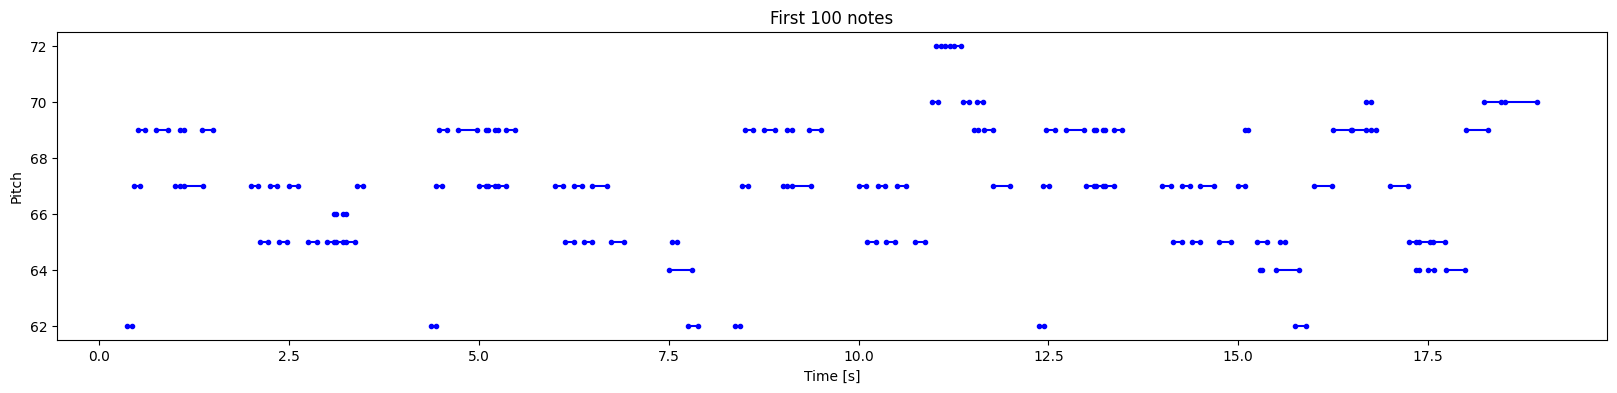

In [38]:
plot_piano_roll(raw_notes, count=100)

Plot the notes for the entire track.

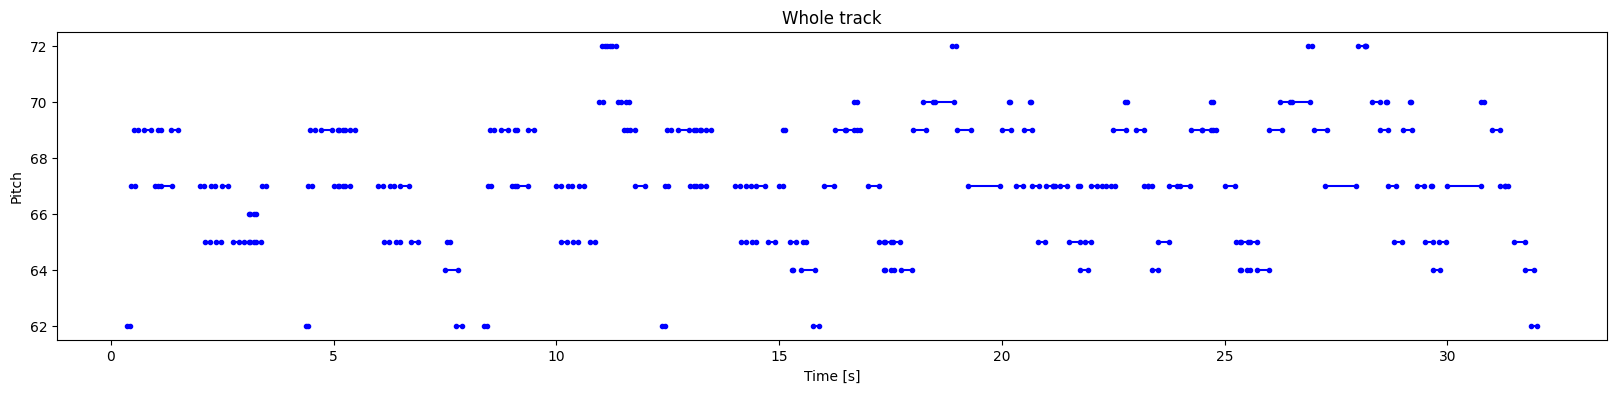

In [39]:
plot_piano_roll(raw_notes)

Check the distribution of each note variable.

In [40]:
def plot_distributions(notes: pd.DataFrame, drop_percentile=2.5):
  plt.figure(figsize=[15, 5])
  plt.subplot(1, 3, 1)
  sns.histplot(notes, x="pitch", bins=20)

  plt.subplot(1, 3, 2)
  max_step = np.percentile(notes['step'], 100 - drop_percentile)
  sns.histplot(notes, x="step", bins=np.linspace(0, max_step, 21))

  plt.subplot(1, 3, 3)
  max_duration = np.percentile(notes['duration'], 100 - drop_percentile)
  sns.histplot(notes, x="duration", bins=np.linspace(0, max_duration, 21))

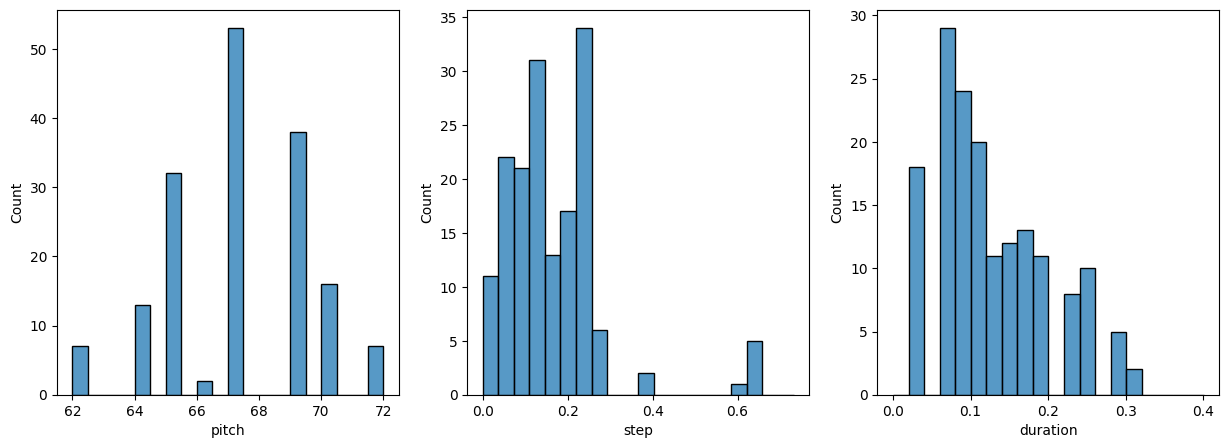

In [41]:
plot_distributions(raw_notes)

## Create a MIDI file

You can generate your own MIDI file from a list of notes using the function below.

In [42]:
def notes_to_midi(
  notes: pd.DataFrame,
  out_file: str,
  instrument_name: str,
  velocity: int = 100,  # note loudness
) -> pretty_midi.PrettyMIDI:

  pm = pretty_midi.PrettyMIDI()
  instrument = pretty_midi.Instrument(
      program=pretty_midi.instrument_name_to_program(
          instrument_name))

  prev_start = 0
  for i, note in notes.iterrows():
    start = float(prev_start + note['step'])
    end = float(start + note['duration'])
    note = pretty_midi.Note(
        velocity=velocity,
        pitch=int(note['pitch']),
        start=start,
        end=end,
    )
    instrument.notes.append(note)
    prev_start = start

  pm.instruments.append(instrument)
  pm.write(out_file)
  return pm

In [43]:
example_file = 'example.midi'
example_pm = notes_to_midi(
    raw_notes, out_file=example_file, instrument_name=instrument_name)

Play the generated MIDI file and see if there is any difference.

In [44]:
display_audio(example_pm)

As before, you can write ```files.download(example_file)``` to download and play this file.

## Create the training dataset


Create the training dataset by extracting notes from the MIDI files. You can start by using a small number of files, and experiment later with more. This may take a couple minutes.

In [45]:
num_files = len(filenames) # Use all available MIDI files
all_notes = []
for f in filenames[:num_files]:
  notes = midi_to_notes(f)
  all_notes.append(notes)

all_notes = pd.concat(all_notes)

In [46]:
n_notes = len(all_notes)
print('Number of notes parsed:', n_notes)

Number of notes parsed: 3460


Next, create a `tf.data.Dataset` from the parsed notes.

In [47]:
key_order = ['pitch', 'step', 'duration']
train_notes = np.stack([all_notes[key] for key in key_order], axis=1)

In [48]:
notes_ds = tf.data.Dataset.from_tensor_slices(train_notes)
notes_ds.element_spec

TensorSpec(shape=(3,), dtype=tf.float64, name=None)

You will train the model on batches of sequences of notes. Each example will consist of a sequence of notes as the input features, and the next note as the label. In this way, the model will be trained to predict the next note in a sequence. You can find a diagram describing this process (and more details) in [Text classification with an RNN](https://www.tensorflow.org/text/tutorials/text_generation).

You can use the handy [window](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#window) function with size `seq_length` to create the features and labels in this format.

In [49]:
def create_sequences(
    dataset: tf.data.Dataset,
    seq_length: int,
    vocab_size = 128,
) -> tf.data.Dataset:
  """Returns TF Dataset of sequence and label examples."""
  seq_length = seq_length+1

  # Take 1 extra for the labels
  windows = dataset.window(seq_length, shift=1, stride=1,
                              drop_remainder=True)

  # `flat_map` flattens the" dataset of datasets" into a dataset of tensors
  flatten = lambda x: x.batch(seq_length, drop_remainder=True)
  sequences = windows.flat_map(flatten)

  # Normalize note pitch
  def scale_pitch(x):
    x = x/[vocab_size,1.0,1.0]
    return x

  # Split the labels
  def split_labels(sequences):
    inputs = sequences[:-1]
    labels_dense = sequences[-1]
    labels = {key:labels_dense[i] for i,key in enumerate(key_order)}

    return scale_pitch(inputs), labels

  return sequences.map(split_labels, num_parallel_calls=tf.data.AUTOTUNE)

Set the sequence length for each example. Experiment with different lengths (e.g. 50, 100, 150) to see which one works best for the data, or use [hyperparameter tuning](https://www.tensorflow.org/tutorials/keras/keras_tuner). The size of the vocabulary (`vocab_size`) is set to 128 representing all the pitches supported by `pretty_midi`.

In [50]:
seq_length = 64
vocab_size = 128
# Re-create sequences with the new length to match model input
seq_ds = create_sequences(notes_ds, seq_length, vocab_size)

The shape of the dataset is ```(100,1)```, meaning that the model will take 100 notes as input, and learn to predict the following note as output.

In [51]:
# Re-check sequence shape to ensure it matches the new seq_length (64)
for seq, target in seq_ds.take(1):
  print('sequence shape:', seq.shape)
  print('sequence elements (first 10):', seq[0: 10])
  print()
  print('target:', target)

sequence shape: (64, 3)
sequence elements (first 10): tf.Tensor(
[[0.5234375  0.         0.08333333]
 [0.5625     0.08333333 0.04166667]
 [0.5390625  0.04166667 0.08333333]
 [0.5390625  0.125      0.078125  ]
 [0.5390625  0.125      0.08333333]
 [0.5546875  0.08333333 0.02604167]
 [0.5390625  0.04166667 0.08333333]
 [0.5546875  0.08333333 0.02604167]
 [0.5234375  0.04166667 0.078125  ]
 [0.5390625  0.11979167 0.109375  ]], shape=(10, 3), dtype=float64)

target: {'pitch': <tf.Tensor: shape=(), dtype=float64, numpy=71.0>, 'step': <tf.Tensor: shape=(), dtype=float64, numpy=0.04166666666666696>, 'duration': <tf.Tensor: shape=(), dtype=float64, numpy=0.03125>}


Batch the examples, and configure the dataset for performance.

In [52]:
batch_size = 64
buffer_size = n_notes - seq_length
train_ds = (seq_ds
            .shuffle(buffer_size)
            .batch(batch_size, drop_remainder=True)
            .cache()
            .prefetch(tf.data.experimental.AUTOTUNE))

In [53]:
train_ds.element_spec

(TensorSpec(shape=(64, 64, 3), dtype=tf.float64, name=None),
 {'pitch': TensorSpec(shape=(64,), dtype=tf.float64, name=None),
  'step': TensorSpec(shape=(64,), dtype=tf.float64, name=None),
  'duration': TensorSpec(shape=(64,), dtype=tf.float64, name=None)})

## Create and train the model

The model will have three outputs, one for each note variable. For `step` and `duration`, you will use a custom loss function based on mean squared error that encourages the model to output non-negative values.

In [54]:
def mse_with_positive_pressure(y_true: tf.Tensor, y_pred: tf.Tensor):
  mse = (y_true - y_pred) ** 2
  positive_pressure = 10 * tf.maximum(-y_pred, 0.0)
  return tf.reduce_mean(mse + positive_pressure)

In [55]:
input_shape = (seq_length, 3)
learning_rate = 0.002

# Re-building the model from scratch to avoid TF variable creation errors
tf.keras.backend.clear_session()

inputs = tf.keras.Input(input_shape)
x = tf.keras.layers.LSTM(256, return_sequences=True)(inputs)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.LSTM(256)(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = {
  'pitch': tf.keras.layers.Dense(128, name='pitch')(x),
  'step': tf.keras.layers.Dense(1, name='step')(x),
  'duration': tf.keras.layers.Dense(1, name='duration')(x),
}

model = tf.keras.Model(inputs, outputs)

loss = {
      'pitch': tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      'step': mse_with_positive_pressure,
      'duration': mse_with_positive_pressure,
}

optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
model.compile(loss=loss, optimizer=optimizer, loss_weights={'pitch': 0.05, 'step': 1.0, 'duration': 1.0})
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64, 256)   │    266,240 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 256)   │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 256)       │    525,312 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration (Dense)    │ (None, 1)         │        257 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pitch (Dense)       │ (None, 128)       │     32,896 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ step (Dense)        │ (None, 1)         │        257 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 824,962 (3.15 MB)

 Trainable params: 824,962 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

Testing the `model.evaluate` function, you can see that the `pitch` loss is significantly greater than the `step` and `duration` losses.
Note that `loss` is the total loss computed by summing all the other losses and is currently dominated by the `pitch` loss.

In [56]:
losses = model.evaluate(train_ds, return_dict=True)
losses

53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - duration_loss: 0.0893 - loss: 0.3597 - pitch_loss: 4.7626 - step_loss: 0.0323


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


{'duration_loss': 0.08934464305639267,
 'loss': 0.3597261905670166,
 'pitch_loss': 4.762599468231201,
 'step_loss': 0.03225156292319298}

One way balance this is to use the `loss_weights` argument to compile:

In [57]:
model.compile(
    loss=loss,
    loss_weights={
        'pitch': 0.05,
        'step': 1.0,
        'duration':1.0,
    },
    optimizer=optimizer,
)

The `loss` then becomes the weighted sum of the individual losses.

In [58]:
model.evaluate(train_ds, return_dict=True)

53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - duration_loss: 0.0893 - loss: 0.3597 - pitch_loss: 4.7626 - step_loss: 0.0323


{'duration_loss': 0.08934464305639267,
 'loss': 0.3597261905670166,
 'pitch_loss': 4.762599468231201,
 'step_loss': 0.03225156292319298}

Train the model.

In [59]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='./training_checkpoints/ckpt_{epoch}.weights.h5',
        save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='loss',
        patience=5,
        verbose=1,
        restore_best_weights=True),
]

In [61]:
%%time
import tensorflow as tf

# Ensure seq_length is defined here
seq_length = 64
epochs = 100

tf.keras.backend.clear_session()

def mse_with_positive_pressure(y_true, y_pred):
  mse = (y_true - y_pred) ** 2
  positive_pressure = 10 * tf.maximum(-y_pred, 0.0)
  return tf.reduce_mean(mse + positive_pressure)

loss_config = {
      'pitch': tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      'step': mse_with_positive_pressure,
      'duration': mse_with_positive_pressure,
}

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='./training_checkpoints/ckpt_{epoch}.weights.h5',
        save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='loss', patience=5, verbose=1, restore_best_weights=True),
]

inputs = tf.keras.Input(shape=(seq_length, 3))
x = tf.keras.layers.LSTM(256, return_sequences=True)(inputs)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.LSTM(256)(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = {
  'pitch': tf.keras.layers.Dense(128, name='pitch')(x),
  'step': tf.keras.layers.Dense(1, name='step')(x),
  'duration': tf.keras.layers.Dense(1, name='duration')(x),
}

model = tf.keras.Model(inputs, outputs)
model.compile(
    loss=loss_config,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss_weights={'pitch': 0.05, 'step': 1.0, 'duration': 1.0}
)

print('Starting training on transposed melody dataset...')
history = model.fit(train_ds, epochs=epochs, callbacks=callbacks, verbose=1)

Starting training on transposed melody dataset...
Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - duration_loss: 0.0276 - loss: 0.2736 - pitch_loss: 4.5527 - step_loss: 0.0184
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - duration_loss: 0.0114 - loss: 0.2568 - pitch_loss: 4.0114 - step_loss: 0.0449
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - duration_loss: 0.0115 - loss: 0.1942 - pitch_loss: 3.2376 - step_loss: 0.0208
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - duration_loss: 0.0108 - loss: 0.1779 - pitch_loss: 3.0219 - step_loss: 0.0159
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - duration_loss: 0.0101 - loss: 0.1755 - pitch_loss: 2.9941 - step_loss: 0.0157
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - duration_loss: 0.0093 - loss: 0.1735 - pitch_loss: 2.9828 - step_loss: 0.0151
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - duration_loss: 0.0093 - loss: 0.1731 - pitch_loss: 2.9699 - step_loss: 0.0152
Epoch 8/100
53/53 ━━━━━━━━

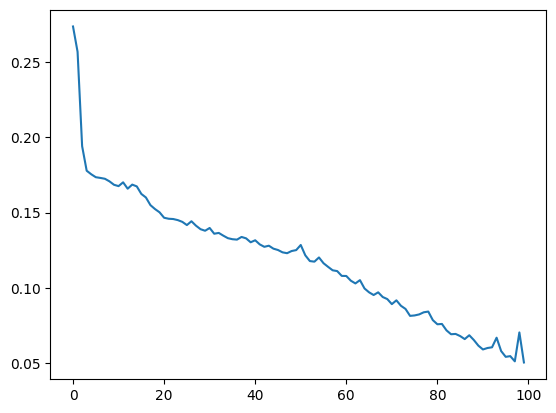

In [62]:
plt.plot(history.epoch, history.history['loss'], label='total loss')
plt.show()

## Generate notes

To use the model to generate notes, you will first need to provide a starting sequence of notes. The function below generates one note from a sequence of notes.

For note pitch, it draws a sample from the softmax distribution of notes produced by the model, and does not simply pick the note with the highest probability.
Always picking the note with the highest probability would lead to repetitive sequences of notes being generated.

The `temperature` parameter can be used to control the randomness of notes generated. You can find more details on temperature in [Text generation with an RNN](https://www.tensorflow.org/text/tutorials/text_generation).

In [63]:
def predict_next_note(
    notes: np.ndarray,
    model: tf.keras.Model,
    temperature: float = 1.0) -> tuple[int, float, float]:
  """Generates a note with strict numerical casting and rhythm snapping."""

  inputs = tf.expand_dims(notes, 0)
  predictions = model.predict(inputs, verbose=0)

  pitch_logits = predictions['pitch']
  step = predictions['step']
  duration = predictions['duration']

  pitch_logits /= max(temperature, 0.1)
  pitch = tf.random.categorical(pitch_logits, num_samples=1)
  pitch = int(tf.squeeze(pitch).numpy())

  # Ensure step and duration are scalars before rounding
  step_val = float(tf.squeeze(step).numpy())
  dur_val = float(tf.squeeze(duration).numpy())

  grid = 0.0625
  step = np.round(max(0, step_val) / grid) * grid
  duration = np.round(max(grid, dur_val) / grid) * grid

  return pitch, float(step), float(duration)

Now generate some notes. You can play around with temperature and the starting sequence in `next_notes` and see what happens.

In [67]:
temperature = 0.4 # More stability
num_predictions = 120

sample_notes = np.stack([all_notes[key] for key in key_order], axis=1)
input_notes = (sample_notes[:seq_length] / np.array([vocab_size, 1, 1]))

generated_notes = []
prev_start = 0
last_pitch = 69 # Center on A4

for _ in range(num_predictions):
  pitch, step, duration = predict_next_note(input_notes, model, temperature)

  # Strict Melodic Interval Constraint: limit jumps to a Major 7th (11 semitones)
  if abs(pitch - last_pitch) > 11:
      # Smooth the jump by moving it closer to the last pitch within the same octave
      pitch = last_pitch + (pitch % 12 - last_pitch % 12)

  # Keep within a usable solo range (C4 to C6)
  pitch = np.clip(pitch, 60, 84)

  start = prev_start + step
  end = start + duration
  generated_notes.append((pitch, step, duration, start, end))

  new_note = np.array([pitch/vocab_size, step, duration])
  input_notes = np.append(input_notes[1:], [new_note], axis=0)
  prev_start = start
  last_pitch = pitch

generated_notes = pd.DataFrame(generated_notes, columns=(*key_order, 'start', 'end'))

In [68]:
generated_notes.head(10)

,pitch,step,duration,start,end
0,71,0.0625,0.0625,0.0625,0.1250
1,71,0.0625,0.0625,0.1250,0.1875
2,71,0.1250,0.0625,0.2500,0.3125
3,67,0.1250,0.0625,0.3750,0.4375
4,72,0.0625,0.0625,0.4375,0.5000
5,72,0.0625,0.0625,0.5000,0.5625
6,72,0.0625,0.0625,0.5625,0.6250
7,69,0.0625,0.0625,0.6250,0.6875
8,71,0.0625,0.0625,0.6875,0.7500
9,72,0.0625,0.0625,0.7500,0.8125


In [69]:
out_file = 'output_solo_specialized.mid'
out_pm = notes_to_midi(generated_notes, out_file=out_file, instrument_name=instrument_name)
display_audio(out_pm)

You can also download the audio file by adding the two lines below:

```
from google.colab import files
files.download(out_file)
```

Visualize the generated notes.

In [ ]:
plot_piano_roll(generated_notes)

Check the distributions of `pitch`, `step` and `duration`.

In [ ]:
plot_distributions(generated_notes)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In the above plots, you will notice the change in distribution of the note variables.
Since there is a feedback loop between the model's outputs and inputs, the model tends to generate similar sequences of outputs to reduce the loss.
This is particularly relevant for `step` and `duration`, which uses the MSE loss.
For `pitch`, you can increase the randomness by increasing the `temperature` in `predict_next_note`.


## Next steps

This tutorial demonstrated the mechanics of using an RNN to generate sequences of notes from a dataset of MIDI files. To learn more, you can visit the closely related [Text generation with an RNN](https://www.tensorflow.org/text/tutorials/text_generation) tutorial, which contains additional diagrams and explanations.

One of the alternatives to using RNNs for music generation is using GANs. Rather than generating audio, a GAN-based approach can generate an entire sequence in parallel. The Magenta team has done impressive work on this approach with [GANSynth](https://magenta.tensorflow.org/gansynth). You can also find many wonderful music and art projects and open-source code on [Magenta project website](https://magenta.tensorflow.org/).